# BB84 Demonstration

Note that `B` carriers Alice's signal to Bob and `E` and `F` are Eve's probles. The QBER is the fraction of sifted bits where Alice and Bob disagree.

Note that here `X` refers to the diagonal $\{\ket{-}, \ket{+}\}$ basis and `Z` refers to the rectilinear $\{\ket{0}, \ket{1}\}$ basis. The measurement meters conventionally measure in the `Z` basis so a `H` gate in front indicates a measurement in the `X` basis as it rotates the coordinates. When looking at the circuit, the relations are helpful where recall the phase factors ($e^{i\phi}$ are not important for us),

$$
\begin{aligned}
X\ket{0} &= \ket{1}, &
X\ket{1} &= \ket{0},\\
X\ket{+} &= \ket{+}, &
X\ket{-} &= e^{-i\pi}\ket{-},\\
H\ket{0} &= \ket{+}, &
H\ket{1} &= \ket{-},\\
H\ket{+} &= \ket{0}, &
H\ket{-} &= \ket{1}.
\end{aligned}
$$


Look at the [this link](https://quantumchannelzoo.org/) for explainations of the quantum channels.

In [1]:
%matplotlib inline

In [2]:
import numpy as np
import secrets

from modules import *

## Demonstration

To use this library 

## BB84 with Different Attacks

In [3]:
def run(attack, signal_channel=None, sifted_key_index=0, seed=secrets.randbits(128)):
    bb84 = BB84(seed=seed, number_bits=48)
    sifted_indices = [i for i, match in enumerate(bb84.alice_bases == bb84.bob_bases) if match]
    round_index = sifted_indices[sifted_key_index]
    
    alice, bob = bb84.key_generation(attack=attack, signal_channel=signal_channel, record_rounds=[round_index])

    print("Alice's sifted key:", "".join(map(str, alice)))
    print("Bob's sifted key:  ", "".join(map(str, bob)))
    
    if attack is not None:
        guesses = bb84.eve_guesses()
        print("Eve's guesses:     ", "".join(map(str, guesses)))
    print(f"QBER: {sum(alice != bob)}/{len(alice)} = {bb84.qber():.1%}")

    basis = bb84.alice_bases[round_index]
    bb84.display(round_index=round_index, title=f"Sifted Key Index {sifted_key_index} | Alice & Bob Basis: {basis}")

## BB84 with no attacker

On an ideal register the two sifted keys agree at every position.

Alice's sifted key: 10011110011110001011101
Bob's sifted key:   10011110011110001011101
QBER: 0/23 = 0.0%


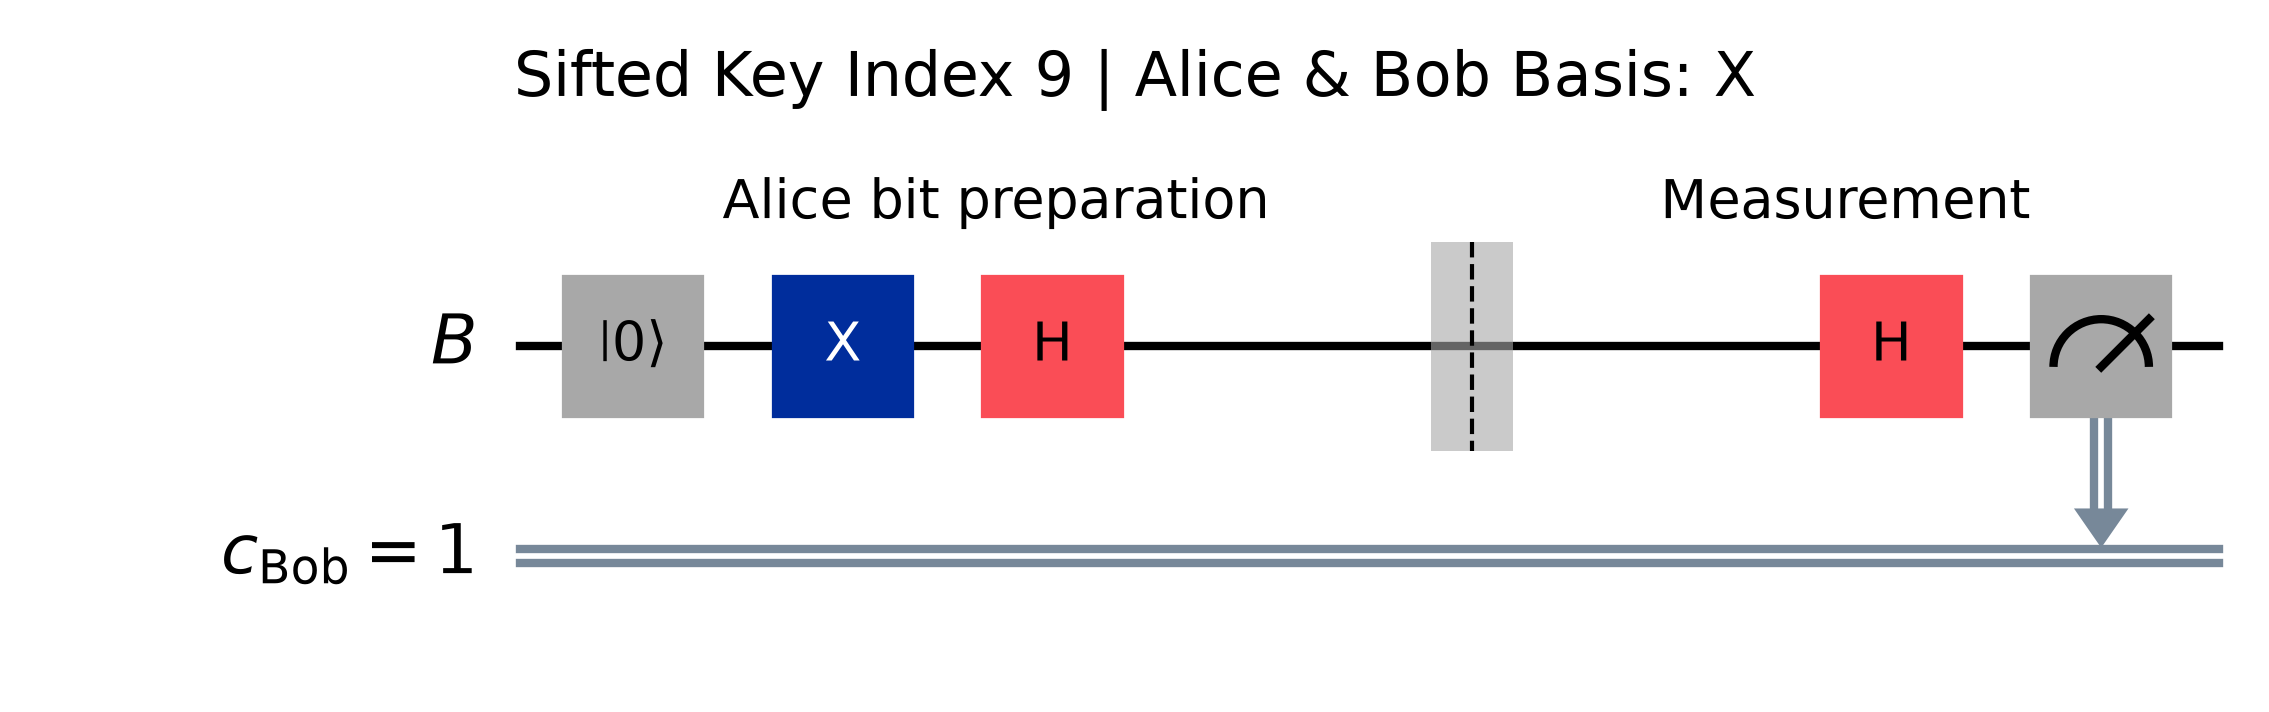

In [29]:
run(attack=None, sifted_key_index=9)

## CNOT attack

Look for the controlled gate from B to E. Eve stores a probe and measures it after the bases are announced.

Alice's sifted key: 10011110011110001011101
Bob's sifted key:   10011110001110011010100
Eve's guesses:      10011010011110011011101
QBER: 4/23 = 17.4%


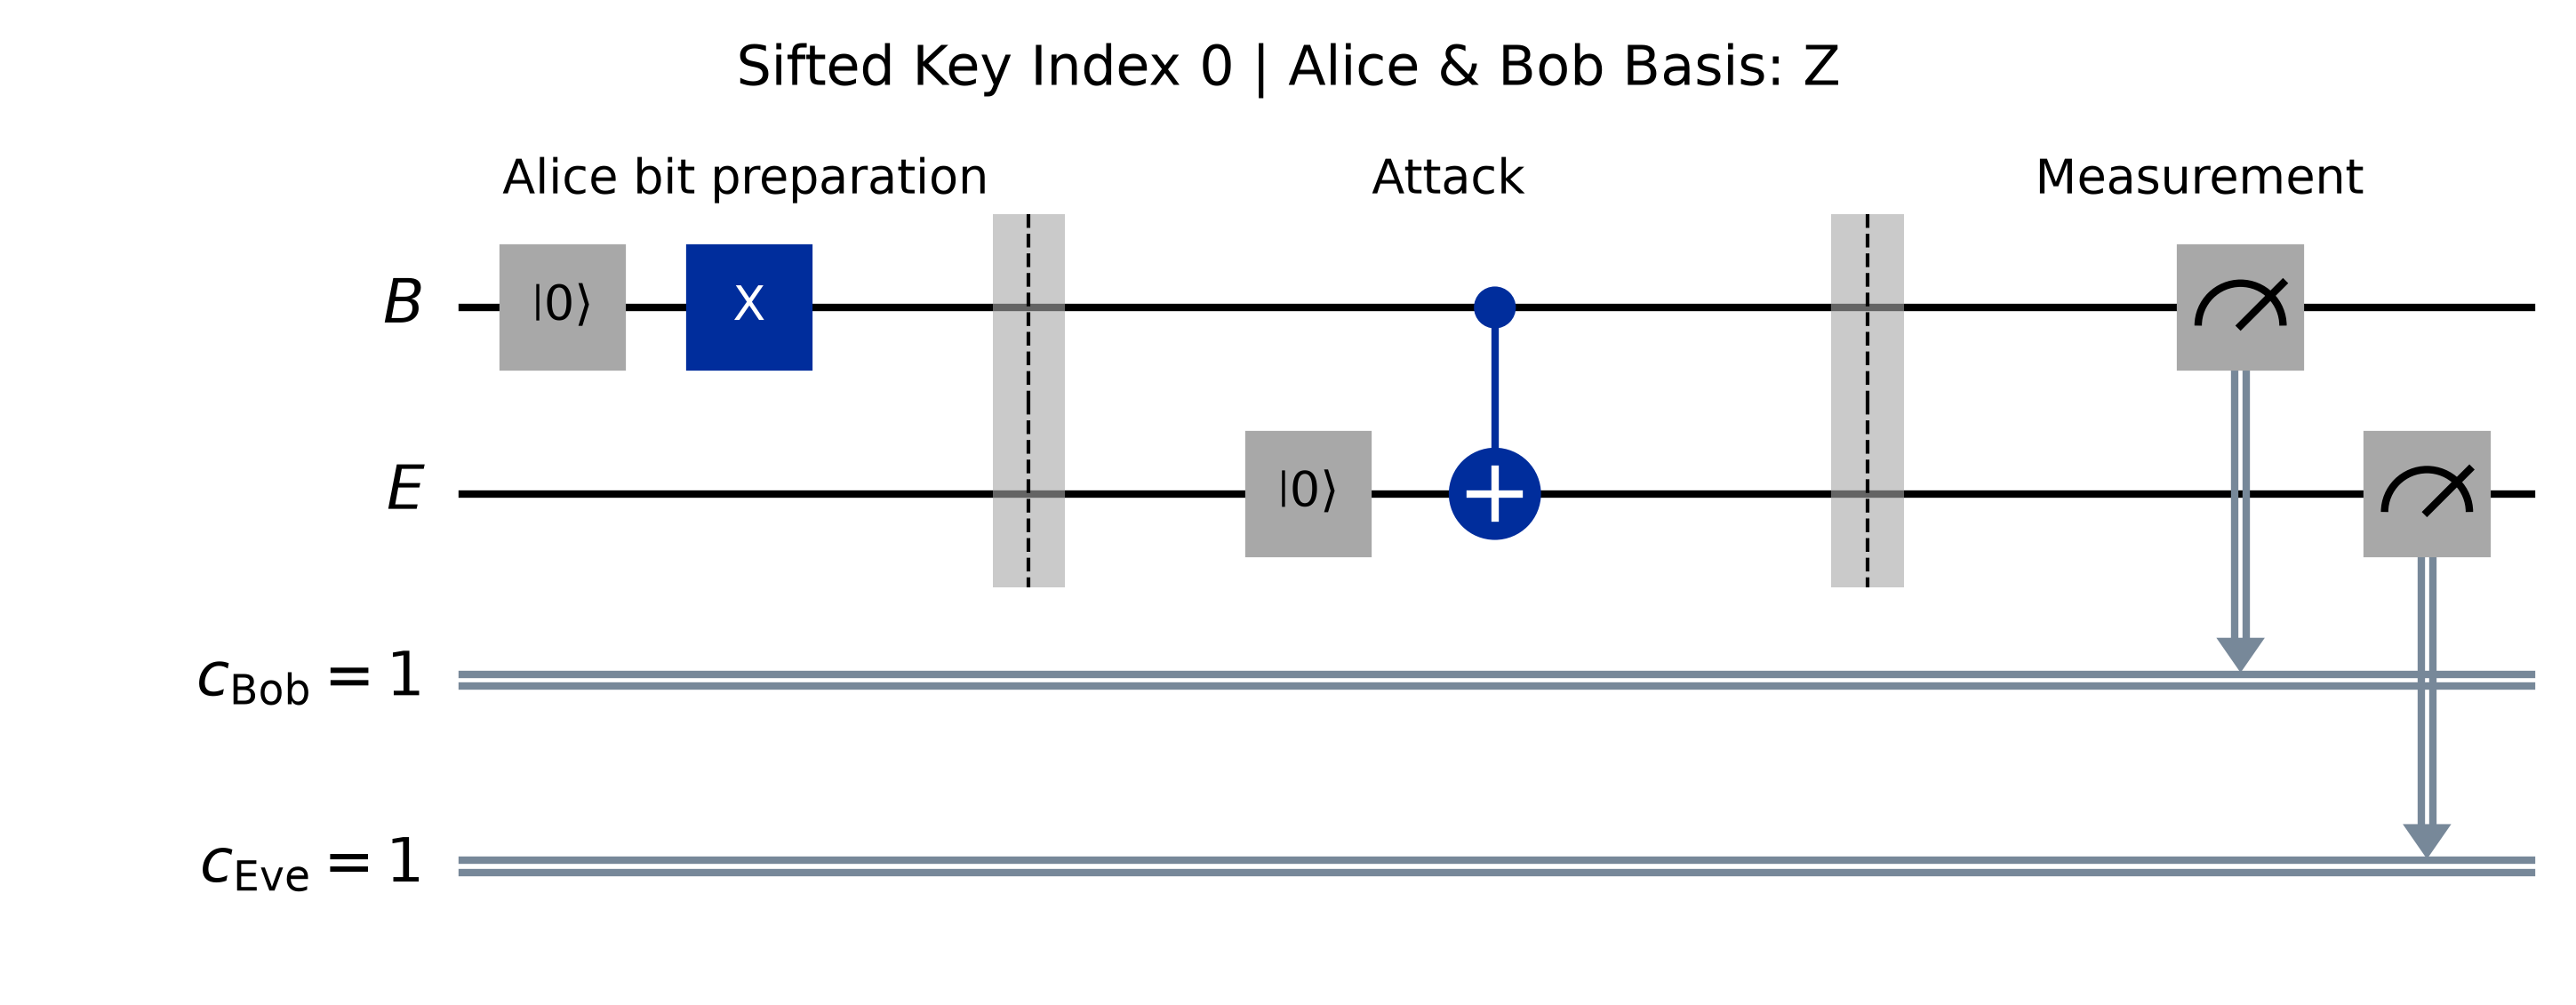

In [5]:
run(attack=CNOTAttack())

## Intercept resend attack

Look for two measurements on B. Eve measures first and sends the resulting state to Bob, who makes the second measurement.

Alice's sifted key: 10011110011110001011101
Bob's sifted key:   10011100010110011000110
Eve's guesses:      10011010011110001001011
QBER: 7/23 = 30.4%


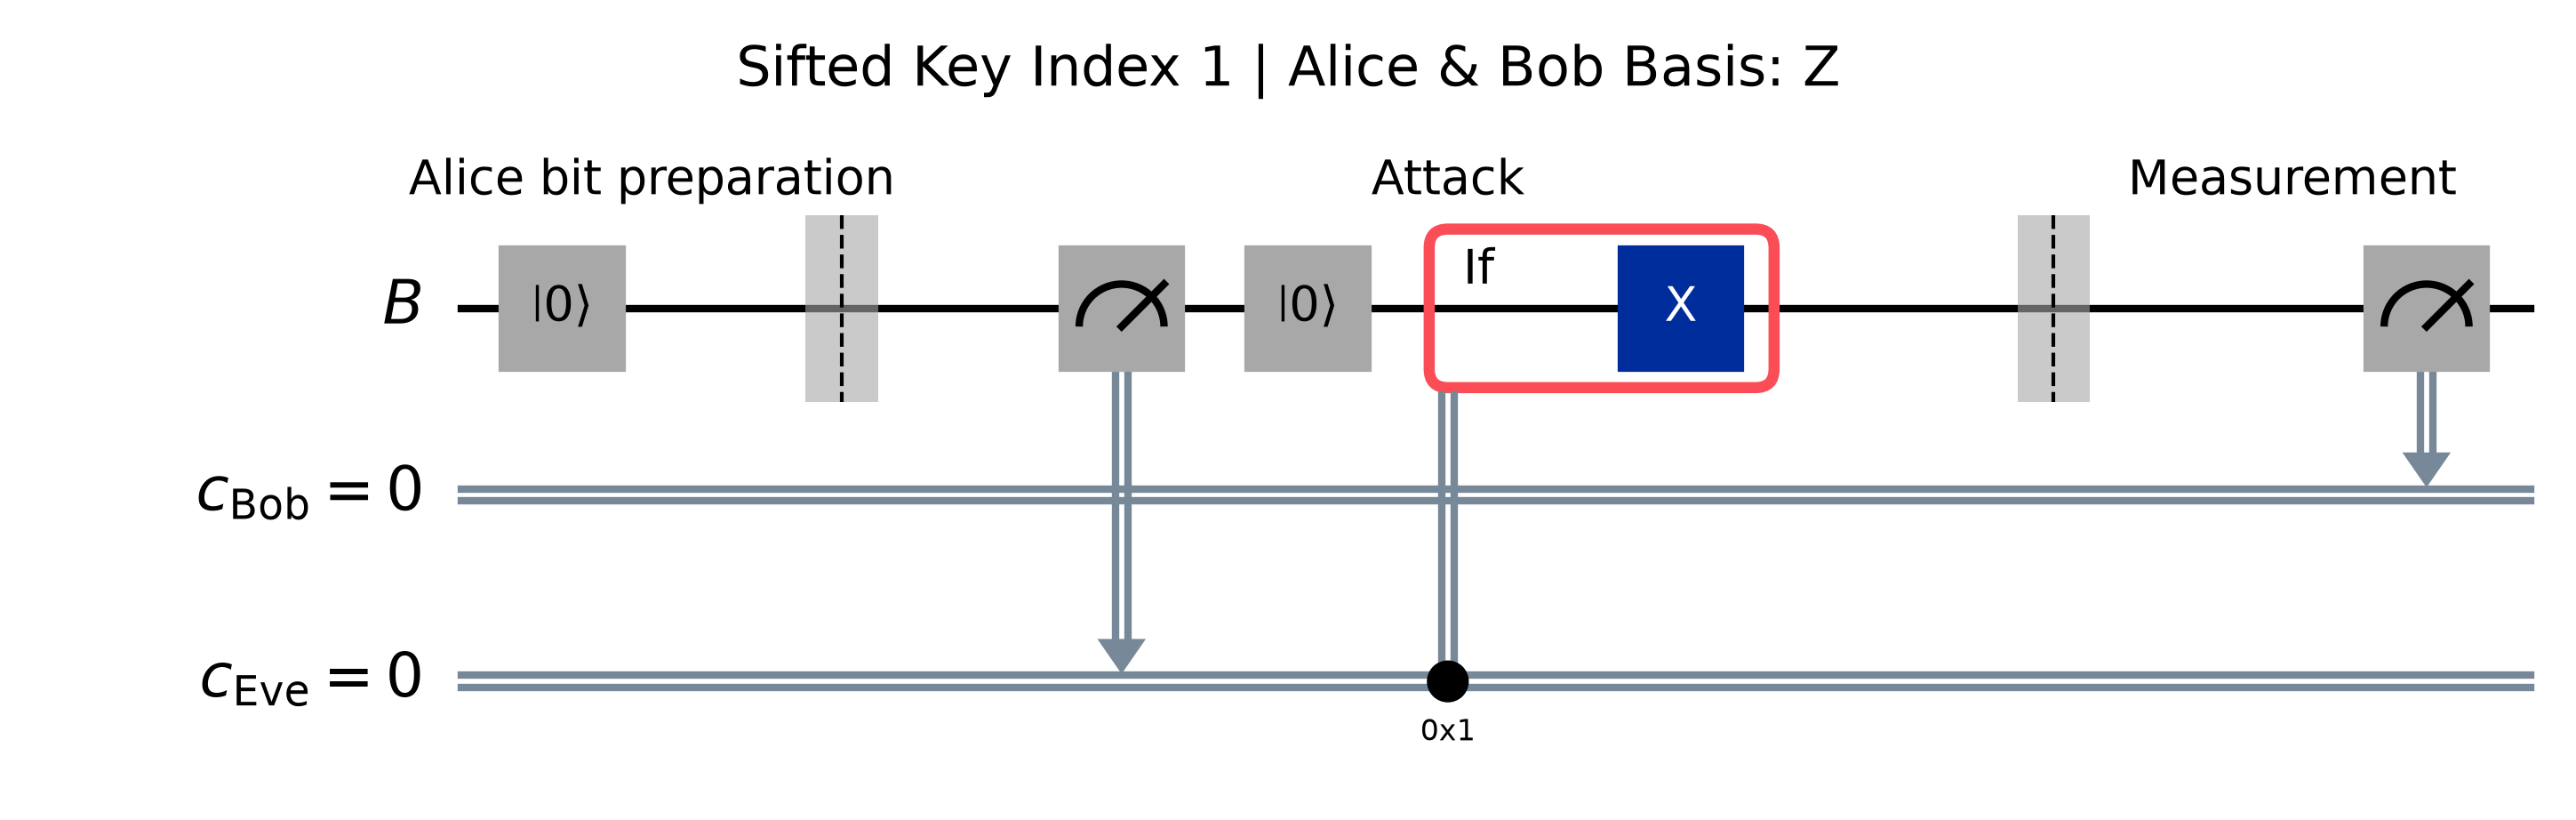

In [6]:
run(attack=InterceptResendAttack(), sifted_key_index=1)

## FGGNP Attack

In the attack outlined by Fuchs et al., Eve couples two probes to the signal. The QBER is give as `qber = disturbance`. Note that from Eve's measurement  

Eve couples two probes to the signal. This run sets the attack disturbance to 10%. Keep it as the reference for the three noisy runs.

Alice's sifted key: 10011110011110001011101
Bob's sifted key:   10011110011110011011101
Eve's guesses:      00001111011110001011100
QBER: 1/23 = 4.3%


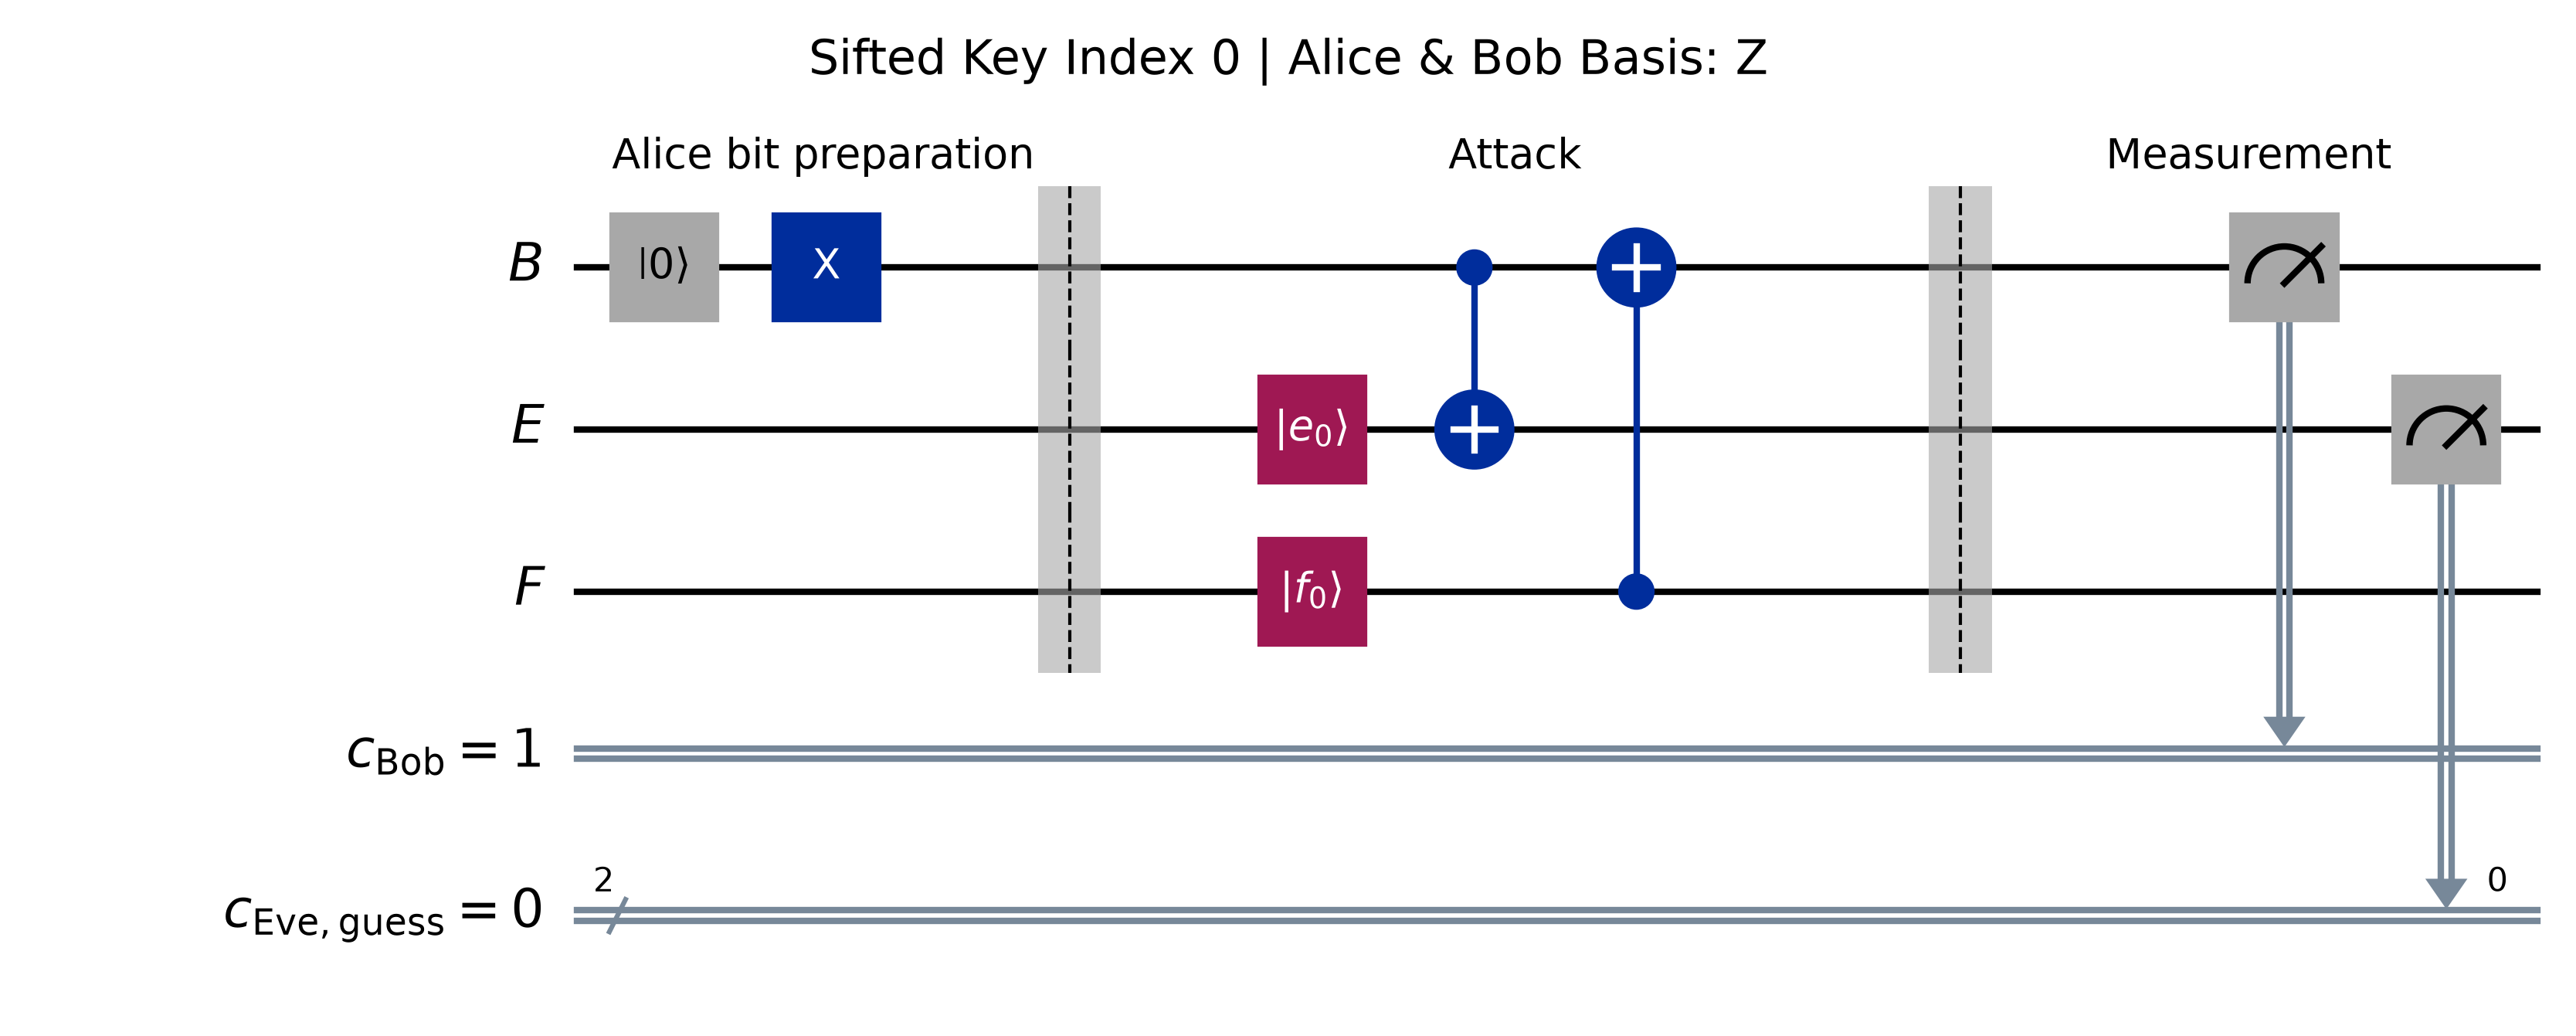

In [7]:
run(attack=FGGNPAttack(disturbance=0.10))

## Breidbart intercept resend attack

This attack, similar to the intercept resend attack takes place in the Breidbart basis which takes place between $X$ and $Z$ basis states. 

Alice's sifted key: 10011110011110001011101
Bob's sifted key:   10111110111100011000100
Eve's guesses:      10111110111100001000101
QBER: 7/23 = 30.4%


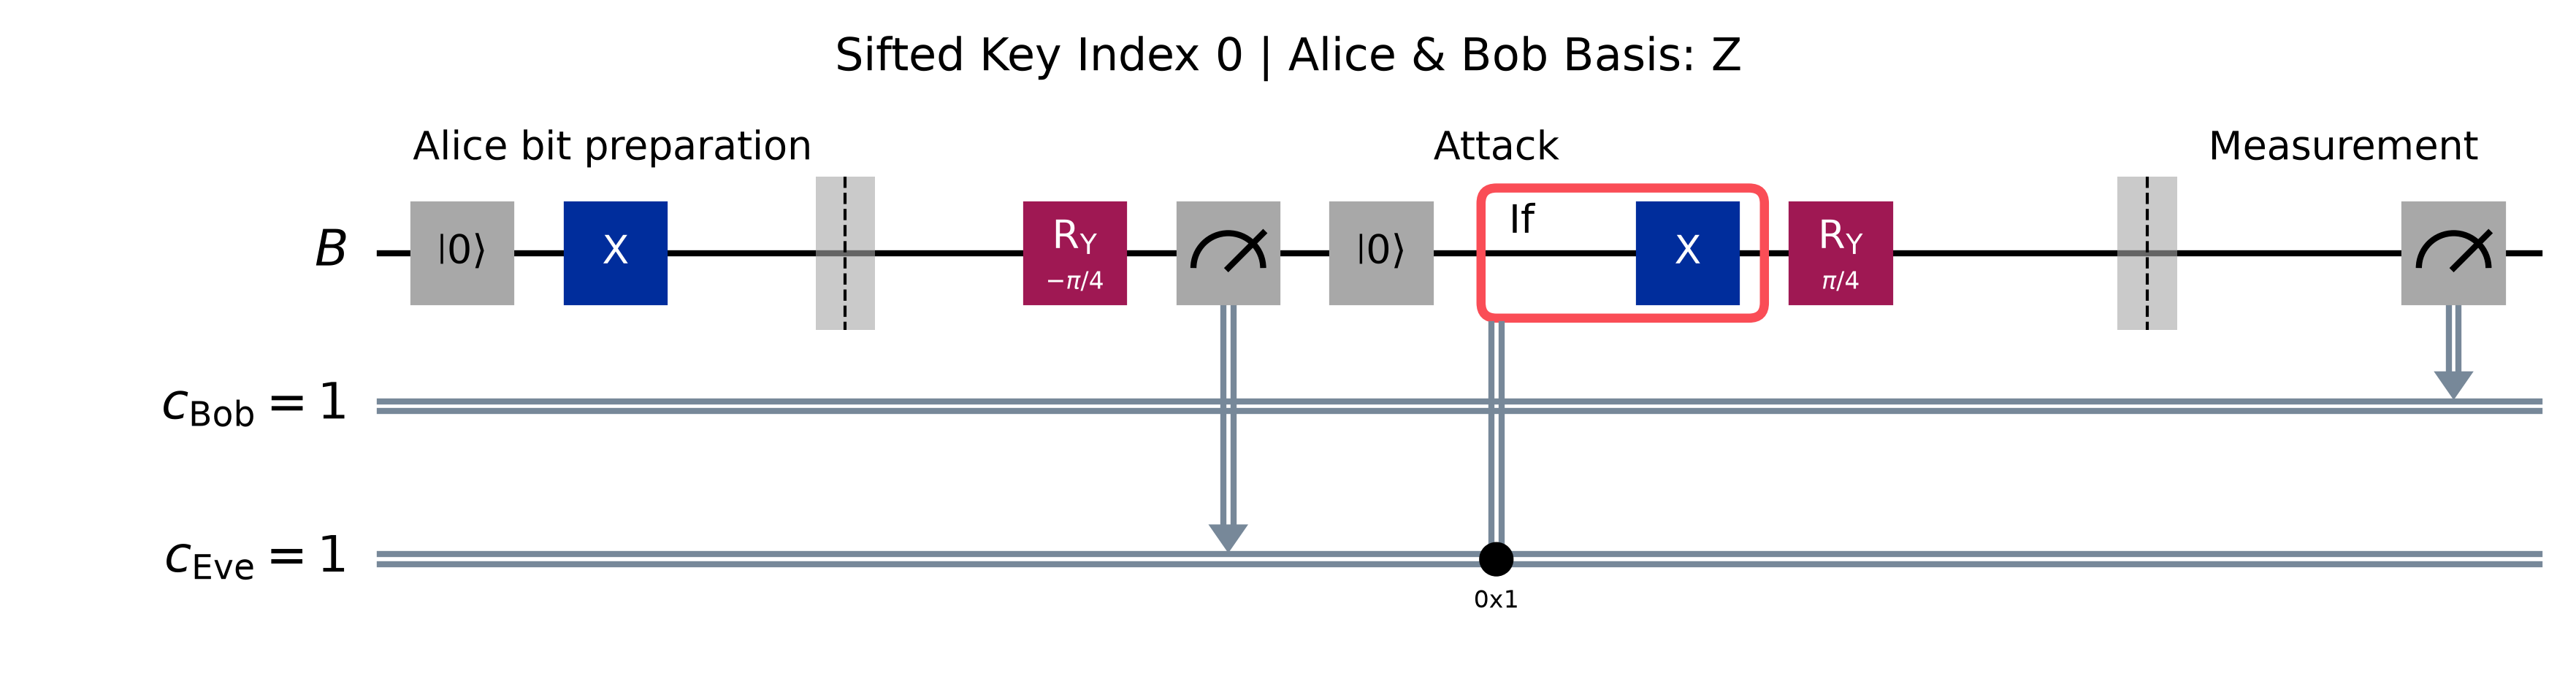

In [8]:
run(attack=BreidbartAttack())

## 

# Adding Noise

In [9]:
def run_fggnp(channel_e, channel_f, sifted_key_index=0, disturbance=0.10, number_bits=48, seed=secrets.randbits(128)):
    bb84 = BB84(number_bits=number_bits, seed=seed)
    attack = FGGNPAttack(disturbance=disturbance, seed=seed)

    # Each channel acts on its named Eve probe after the attack interaction.
    noise = ProbeNoise({"E": channel_e, "F": channel_f})
    alice, bob = bb84.key_generation(attack=attack, memory_channel=noise, memory_targets=list(noise.channels), record_rounds=range(bb84.number_bits))

    sifted_rounds = np.flatnonzero(bb84.sifted_mask) # find original transmission round that produced this sifted bit
    if len(sifted_rounds) == 0:
        raise ValueError("No sifted bits")

    round_index = int(sifted_rounds[sifted_key_index])
    basis = bb84.alice_bases[round_index]

    eve = bb84.eve_guesses()

    def bits(values):
        return "".join("?" if bit == UNKNOWN else str(bit) for bit in values)

    print("Alice's sifted key:", bits(alice))
    print("Bob's sifted key:  ", bits(bob))
    print("Eve's guesses:     ", bits(eve))

    print(f"QBER: {np.count_nonzero(alice != bob)}/{len(alice)} = {bb84.qber():.1%}")

    bb84.display(round_index=round_index, title=f"FGGNP Attack | Sifted bit {sifted_key_index} | {basis} basis")

## FGGNP attack with amplitude damping

This channel acts on B after Eve’s interaction and before Bob measures. An excited state can relax to the ground state with probability 0.30.

Alice's sifted key: 011111100101101111110110100001001000011110001001
Bob's sifted key:   011111100001111111110111101101001000011110001001
Eve's guesses:      011111110111110111010010101011101010011110001011
QBER: 5/48 = 10.4%


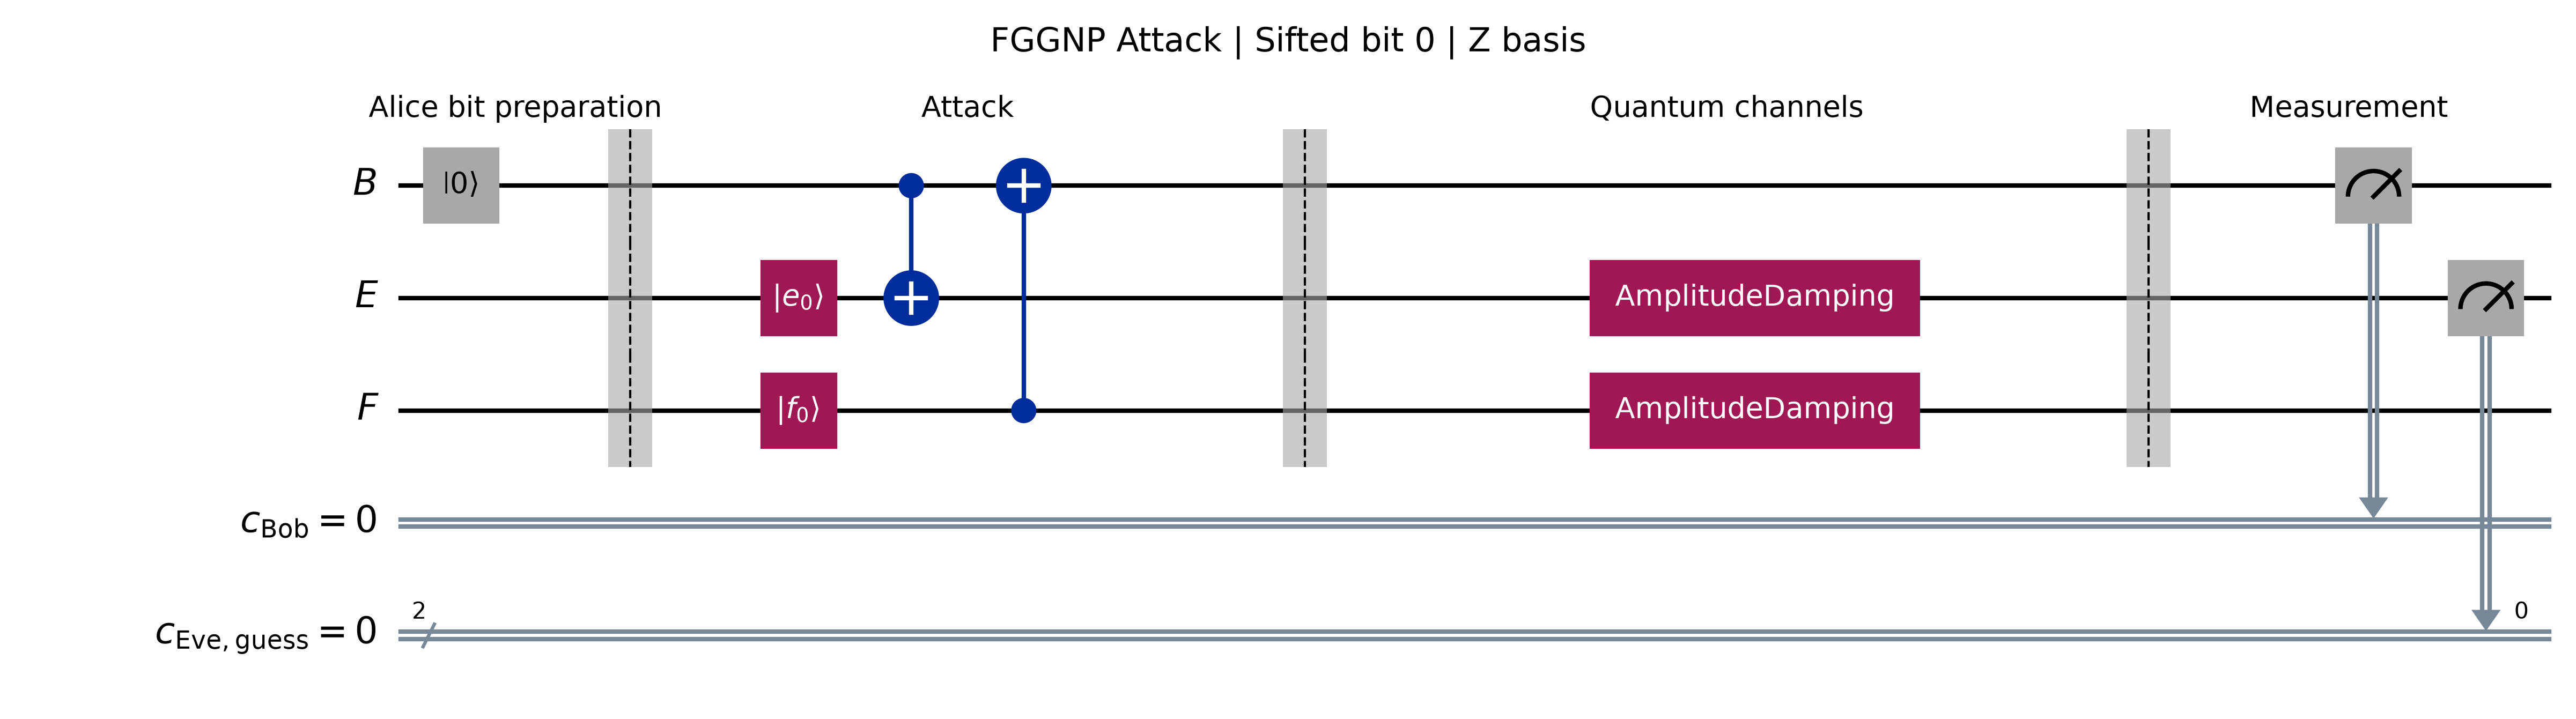

In [18]:
run_fggnp(channel_e=AmplitudeDamping(gamma=0.0), channel_f=AmplitudeDamping(gamma=0.0), number_bits=100)

## FGGNP attack with damping and dephasing

Replace the previous channel with one that combines relaxation (g) and phase noise (p). The channel box appears in the same place on B.

Alice's sifted key: 0100110111000100101101101
Bob's sifted key:   0100110111100100101101100
Eve's guesses:      0011110100010100100101001
QBER: 2/25 = 8.0%


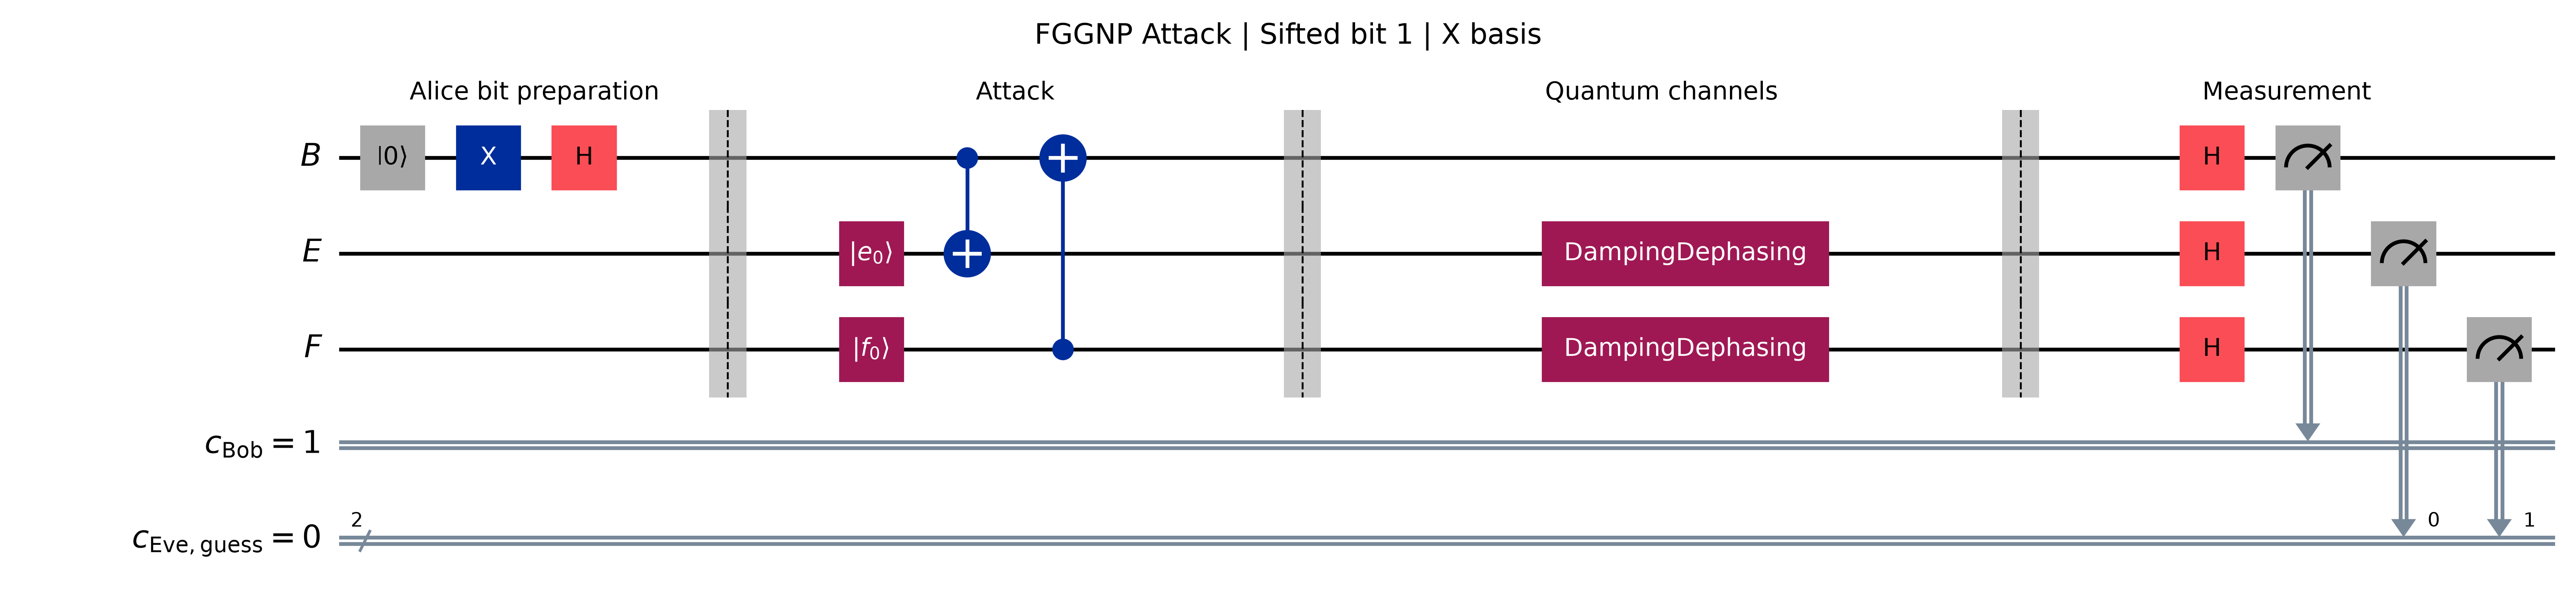

In [28]:
run_fggnp(channel_e=DampingDephasing(p=0.10, g=0.30), channel_f=DampingDephasing(p=0.49, g=0.9), sifted_key_index=1)

## FGGNP attack with depolarizing noise

Here the channel applies an X, Y, or Z error with probability 0.10 each. Compare Bob’s key with the FGGNP-only run. The displayed QBER is a sample from 48 signals.

Alice's sifted key: 0100110111000100101101101
Bob's sifted key:   0100110111100100101101100
Eve's guesses:      0011010110000100100111111
QBER: 2/25 = 8.0%


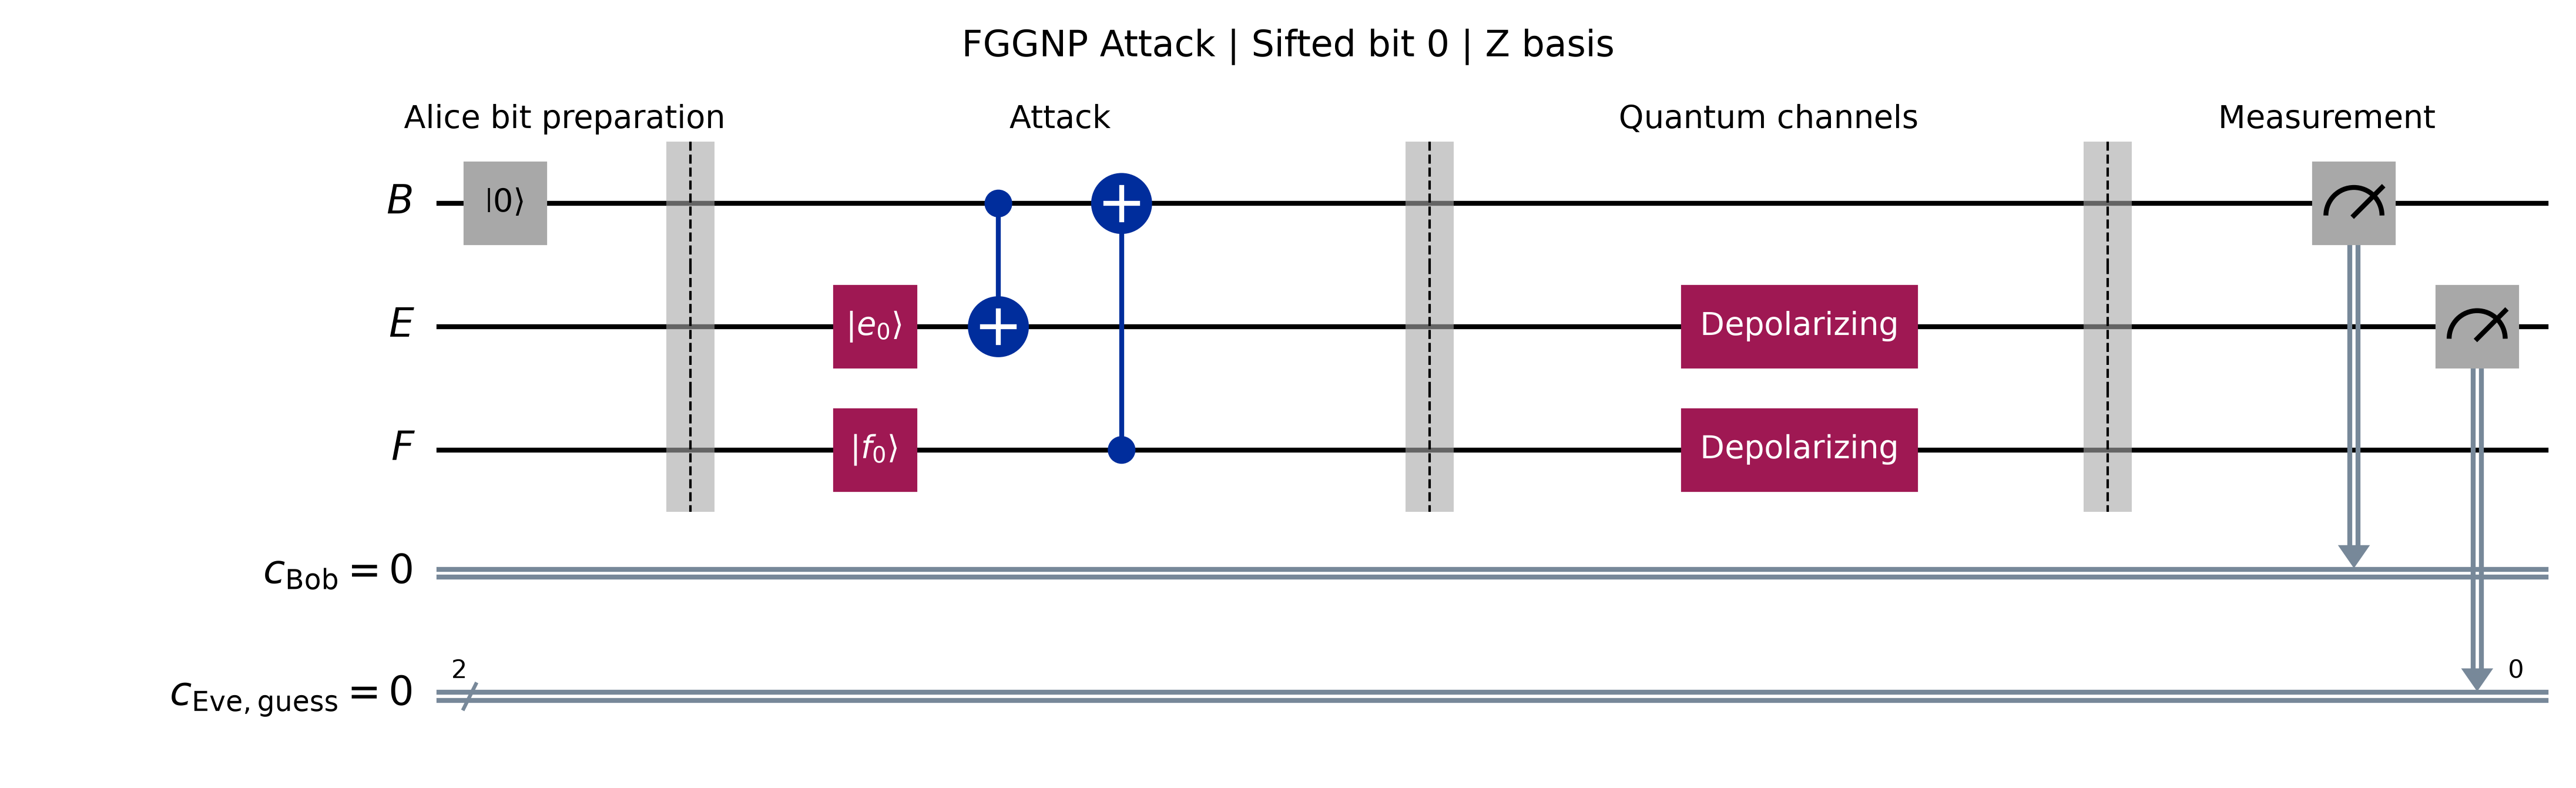

In [12]:
run_fggnp(channel_e=Depolarizing(p=0.49), channel_f=Depolarizing(p=0.49))